# Do modelo aos mecanismos: conexões com a disciplina

Nestor, Letícia e Gabriel - MAE5920. Este notebook lê execuções concluídas e confere os artefatos, sem repetir os treinos. As novas figuras são originais. Fontes: Prince, capítulos 6-9 e 11, e os slides correspondentes disponíveis ao grupo. O material do curso sustenta as conexões; os exemplos abaixo são elaboração didática própria.

**Roteiro:** otimização → profundidade e inicialização → regularização → double descent. Os ensaios sintéticos e a classificação IMDb aparecem identificados separadamente.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'didactic_config.json').exists())
Q=ROOT/'results/didactic'
read=lambda p: json.loads((ROOT/p).read_text())
def plot(name): display(Image(filename=str(Q/'figures'/f'{name}.png')))
cfg=read('didactic_config.json')
frozen=read('results/didactic/selection_frozen.json')
records=[json.loads(p.read_text()) for p in sorted((Q/'runs').glob('*.json'))]
audit=pd.read_csv(Q/'audit_metrics.csv')
print(len(records),'treinos; ',len(audit),'checkpoints na auditoria interna')

51 treinos;  42 checkpoints na auditoria interna


## Dados e regras antes da comparação

Somente o antigo treino limpo do IMDb é repartido: 6.144 para ajuste, 1.536 para validação e 2.048 para auditoria interna. Não consultamos novamente o teste oficial. Vocabulário TF-IDF, IDF, SVD de 128 componentes e padronização usam somente os 6.144 exemplos de treino. As redes densas recebem a mesma representação. Este não é um novo leaderboard CNN/BERT/Qwen.

As sementes 17, 29 e 43 são fixas. Cada comparação de otimizadores compartilha pesos iniciais e ordem de minibatches. A auditoria foi transferida para o ambiente de execução apenas após o congelamento; uma correção técnica posterior de precisão, sem retuning, está documentada.

In [2]:
manifest=read('results/didactic/data_manifest.json')
display(pd.DataFrame([{'papel':k,'n':v['n'],'negativos':v['label_counts']['0'],'positivos':v['label_counts']['1']} for k,v in manifest['roles'].items()]))
for a,aa in manifest['roles'].items():
    for b,bb in manifest['roles'].items():
        if a!=b: assert set(aa['text_sha256']).isdisjoint(bb['text_sha256'])
assert manifest['official_test_opened'] is False

,papel,n,negativos,positivos
0,train,6144,3072,3072
1,validation,1536,768,768
2,audit,2048,1024,1024


## 1. Otimização: taxa, memória e adaptação

**Prince 6.1-6.5; slides Ajuste de Modelos, páginas do arquivo 26-39.** No exemplo quadrático, os autovalores da Hessiana são 0,5 e 20: GD é estável para taxa entre 0 e 0,1. O painel é determinístico, sem minibatches; suas taxas ilustram trajetórias e não constituem um ranking justo.

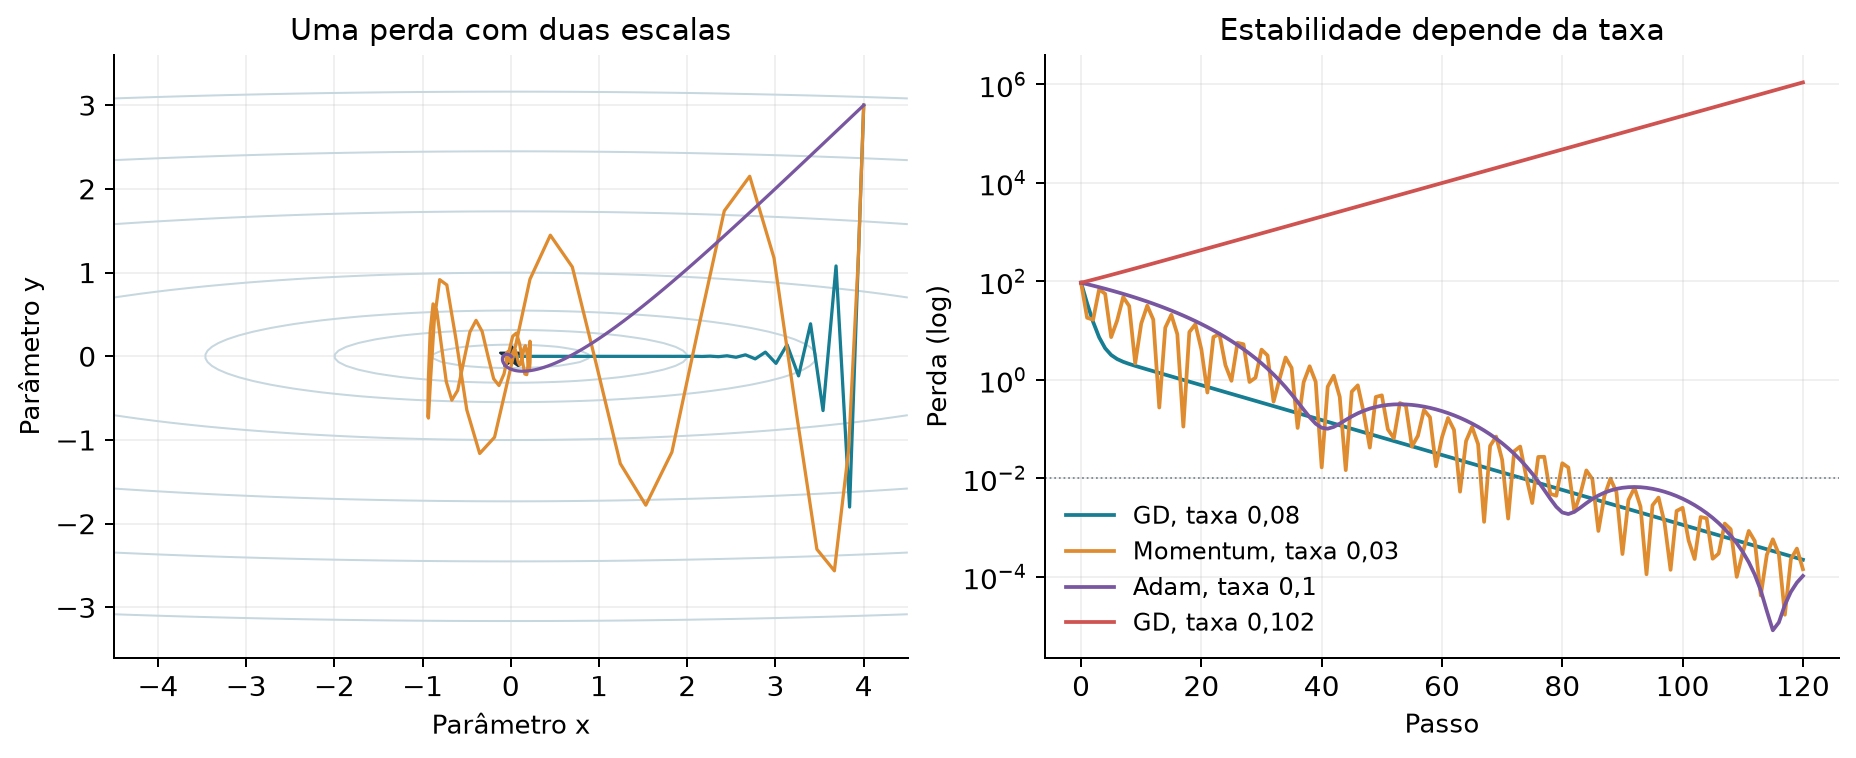

,condition,lr,loss
120,gd_stable,0.080,2.224108e-04
241,gd_unstable,0.102,1.102158e+06
362,momentum,0.030,1.429312e-04
483,adam,0.100,1.042513e-04


In [3]:
plot('quadratic')
q=pd.read_csv(Q/'quadratic.csv')
display(q.loc[q.step==q.step.max(),['condition','lr','loss']])

### A mesma pergunta em resenhas reais

MLP com duas camadas ocultas de 64 unidades, sem dropout/L2; 32 épocas. Primeiro, todos usam taxa 0,003. Depois, cada método recebe três candidatas, com a escolha pela menor CE final média de validação nas três sementes. Comparar somente uma taxa comum mistura o algoritmo com sua adequação à escala do problema. O momentum do PyTorch usa v ← 0,9v + g; a convenção difere da média móvel normalizada por um fator constante na taxa.

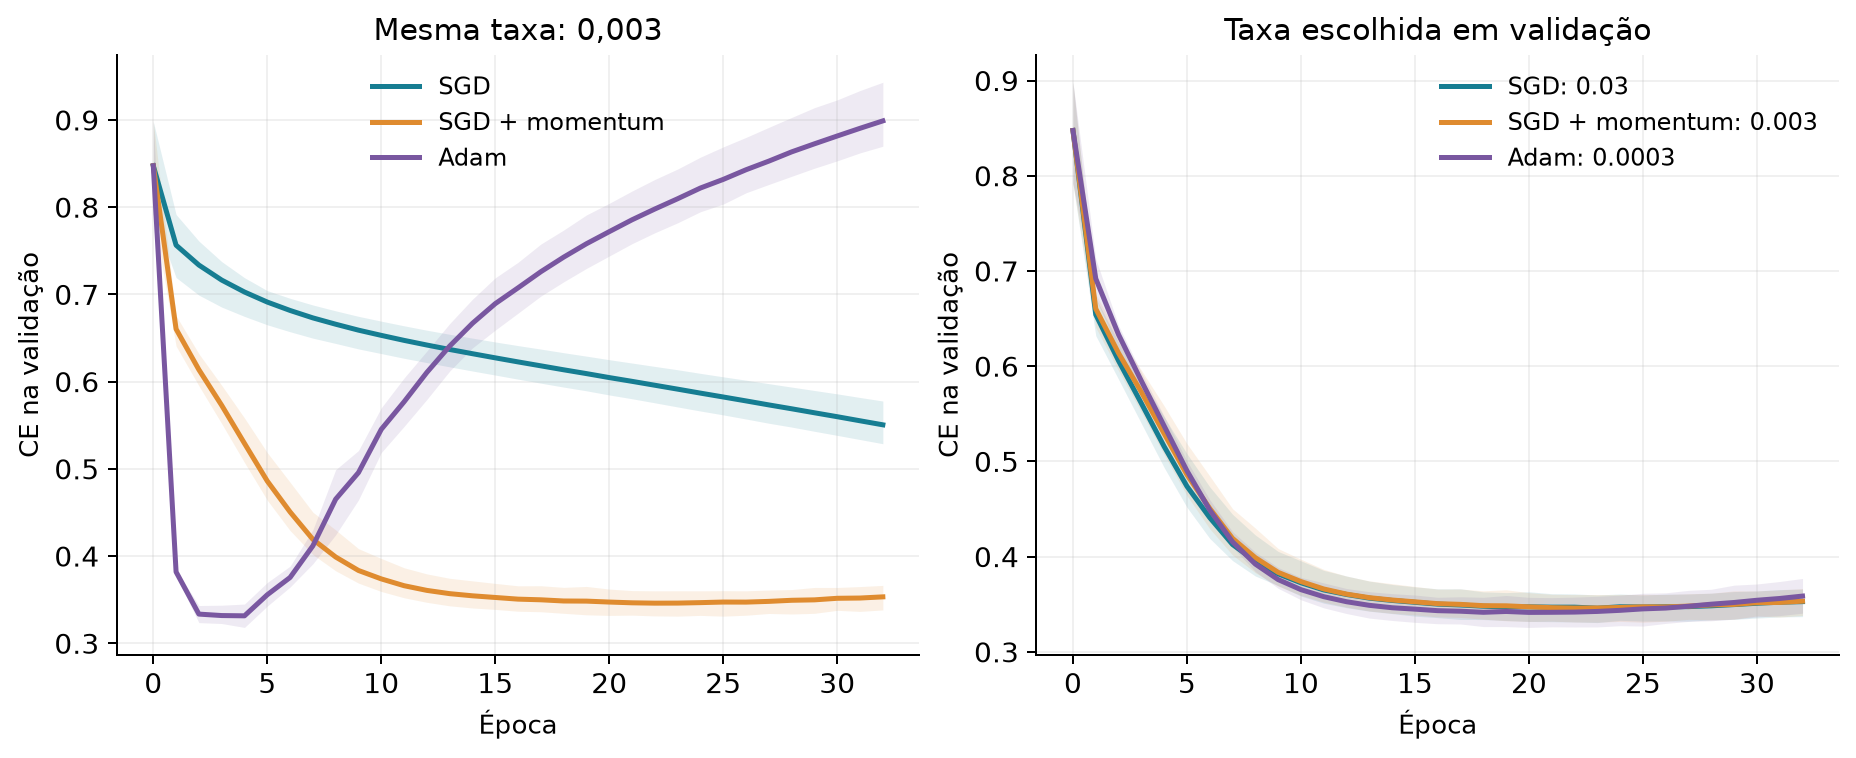

,taxa escolhida,0.003,0.03,0.3,0.0003
sgd,0.0300,0.550551,0.352809,0.805483,NaN
momentum,0.0030,0.353290,0.818420,1.397509,NaN
adam,0.0003,0.899019,1.074353,NaN,0.358635


In [4]:
plot('optimizers')
display(pd.DataFrame({k:{'taxa escolhida':v['lr'],**v['mean_final_validation_ce_by_lr']} for k,v in frozen['optimizer_choices'].items()}).T)

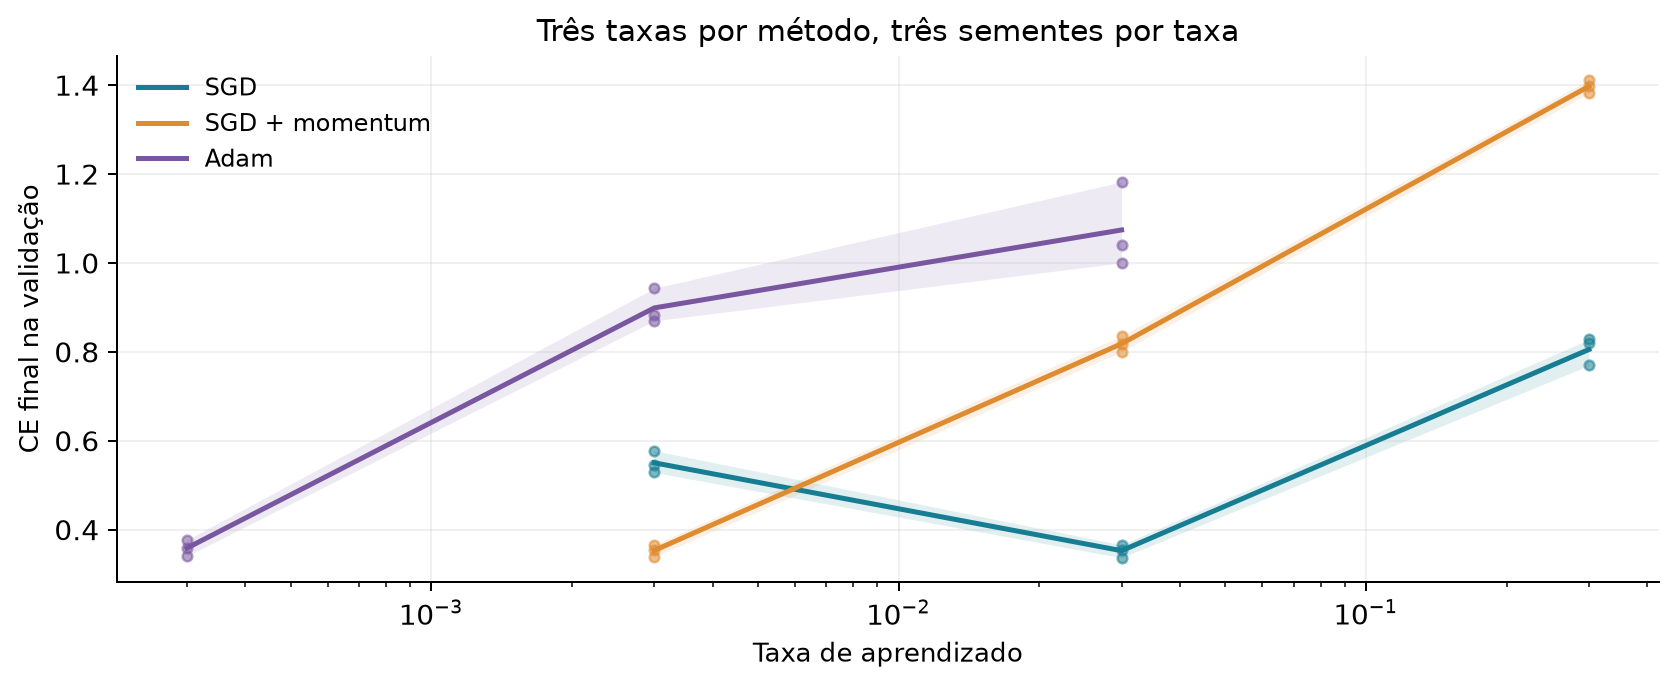

Partidas e minibatches idênticos por semente confirmados.


In [5]:
plot('learning_rates')
for seed in cfg['seeds']:
    rr=[r for r in records if r['group']=='optimizers' and r['seed']==seed]
    assert len({r['initial_state_sha256'] for r in rr})==1
    assert len({r['minibatch_order_sha256'] for r in rr})==1
print('Partidas e minibatches idênticos por semente confirmados.')

## 2. Mais camadas, atalhos e escala

**Prince 11.1-11.3; slides Redes Residuais, páginas 5-18.** Comparamos 1, 4 e 12 camadas ocultas e duas variantes de 12 camadas com atalho. As três redes de 12 camadas têm exatamente os mesmos parâmetros e pesos iniciais. Sem atalho: h ← f(ReLU(h)); com atalho: h ← h + s f(ReLU(h)). A comparação com s=1 isola a soma identidade. Em seguida, s=1/√11 controla a escala do ramo residual. Não há BatchNorm/LayerNorm nessas ablações. Todas usam a taxa Adam já escolhida, sem retuning por arquitetura.

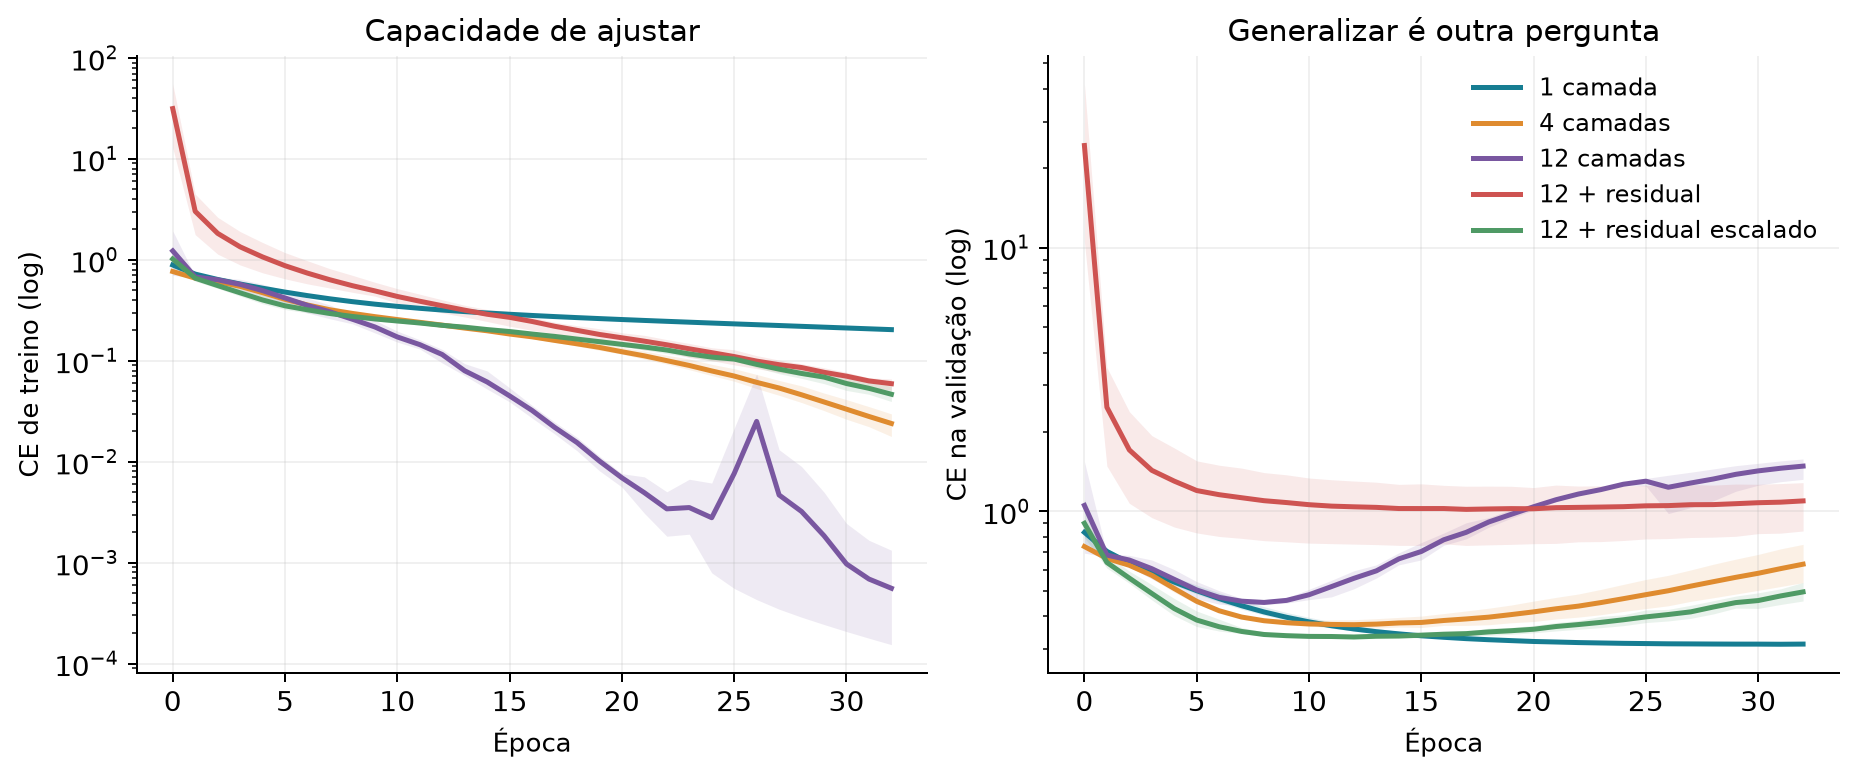

,parâmetros,CE treino final,CE validação final
arquitetura,,,
plain_1,8386.0,0.203379,0.314190
plain_12,54146.0,0.000558,1.484406
plain_4,20866.0,0.023920,0.630828
residual_12_raw,54146.0,0.059292,1.095812
residual_12_scaled,54146.0,0.046602,0.495302


In [6]:
plot('architectures')
display(pd.DataFrame([{'arquitetura':r['name'],'parâmetros':r['parameters'],'CE treino final':r['history'][-1]['train_ce'],'CE validação final':r['history'][-1]['validation_ce']} for r in records if r['group']=='architectures']).groupby('arquitetura').mean())

## 3. A inicialização deixa o sinal sobreviver?

**Prince 7.5; slides Gradientes e Inicialização, páginas 31-42.** Diagnóstico sintético, sem treino: 32 camadas ReLU de largura 64, entradas gaussianas e uma sonda linear fixa. A variância dos pesos é g²·2/64, com g em {0,1; 1; 3}. Para cada semente, reutilizamos os mesmos pesos gaussianos de base e o mesmo gradiente na saída. Os eixos são logarítmicos. A retropropagação percorre as camadas da direita para a esquerda. He é uma aproximação de preservação de escala, não a promessa de variância exatamente constante numa rede finita.

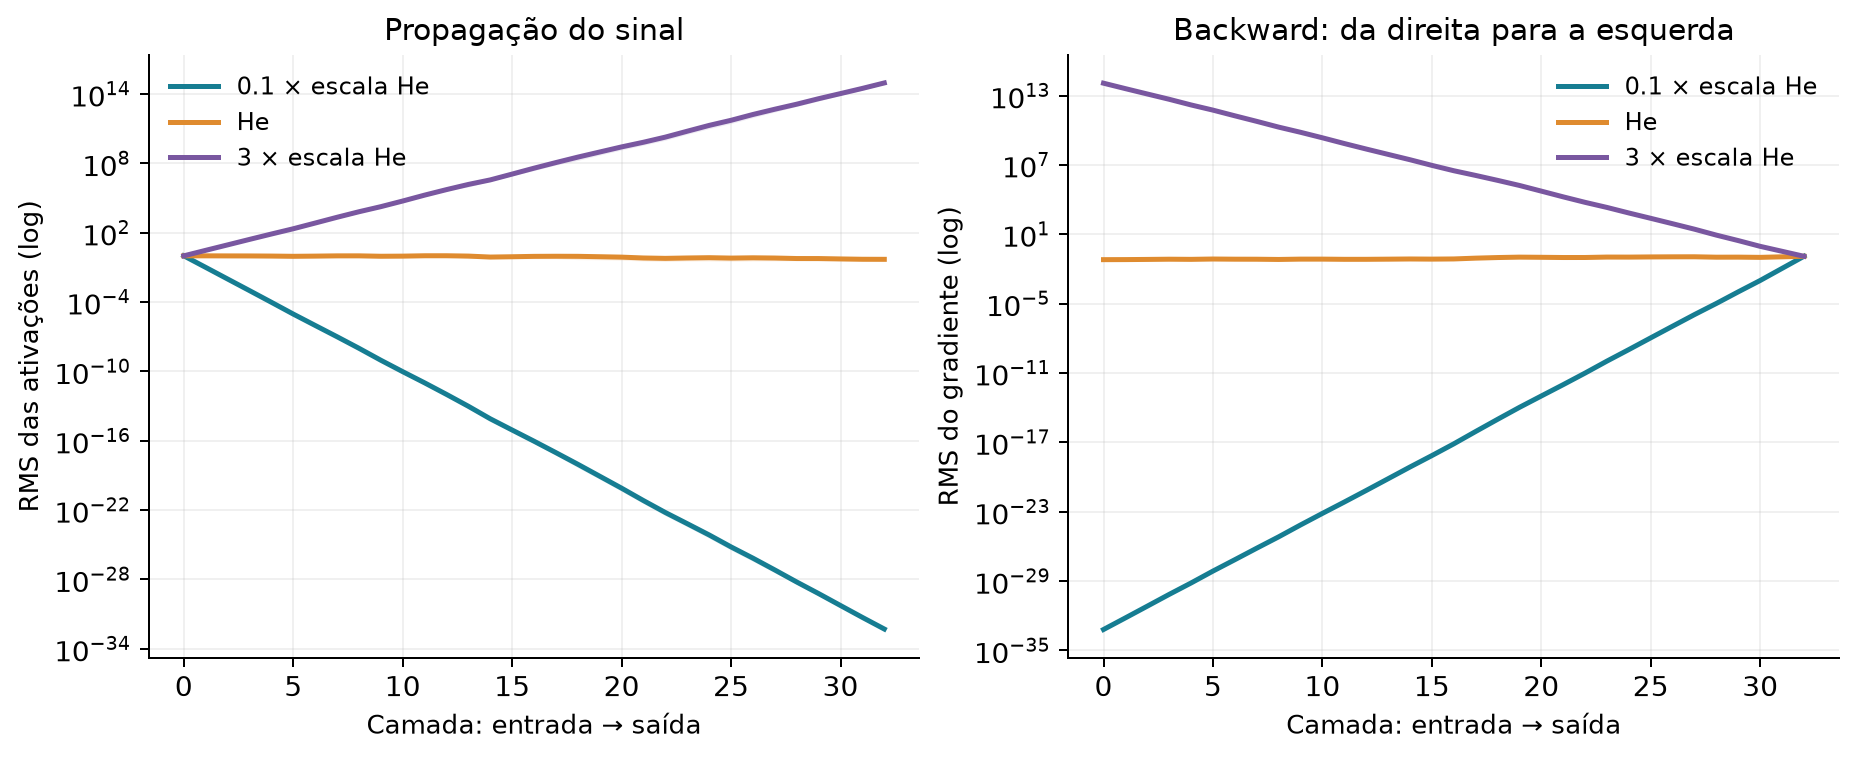

activation_rms  gradient_rms
gain layer                              
0.1  0        9.980463e-01  6.396452e-34
     32       4.968559e-33  1.250000e-01
1.0  0        9.980463e-01  6.396452e-02
     32       4.968559e-01  1.250000e-01
3.0  0        9.980463e-01  1.185275e+14
     32       9.206840e+14  1.250000e-01

In [7]:
plot('initialization')
ini=pd.read_csv(Q/'initialization.csv')
display(ini.loc[ini.layer.isin([0,32])].groupby(['gain','layer'])[['activation_rms','gradient_rms']].mean())

## 4. Ajustar melhor o treino pode piorar a validação

**Prince 9.1 e 9.3; slides Regularização, páginas 7-17 e 29-36.** Agora só 512 exemplos recebem supervisão: MLP de três camadas de 128 unidades, 120 épocas e a taxa Adam já congelada. Comparamos nenhuma penalização, dropout 0,5 e L2 explícita. A representação sem rótulos continua sendo aquela ajustada nos 6.144 exemplos do treino comum. L2 entra como lambda/2 vezes a soma dos pesos ao quadrado, excluindo vieses; Adam usa weight_decay=0. As curvas de CE são medidas em modo avaliação, com dropout desligado, e não incluem a penalização L2.

A parada usa paciência 15 e melhora mínima de 0,0001 na validação. Continuamos o treino para visualizar a trajetória contrafactual, preservando o checkpoint escolhido até a parada. Isso não mede economia real de tempo. A escolha por CE pode reduzir a confiança errada sem maximizar a acurácia; dropout também pode subajustar com este orçamento.

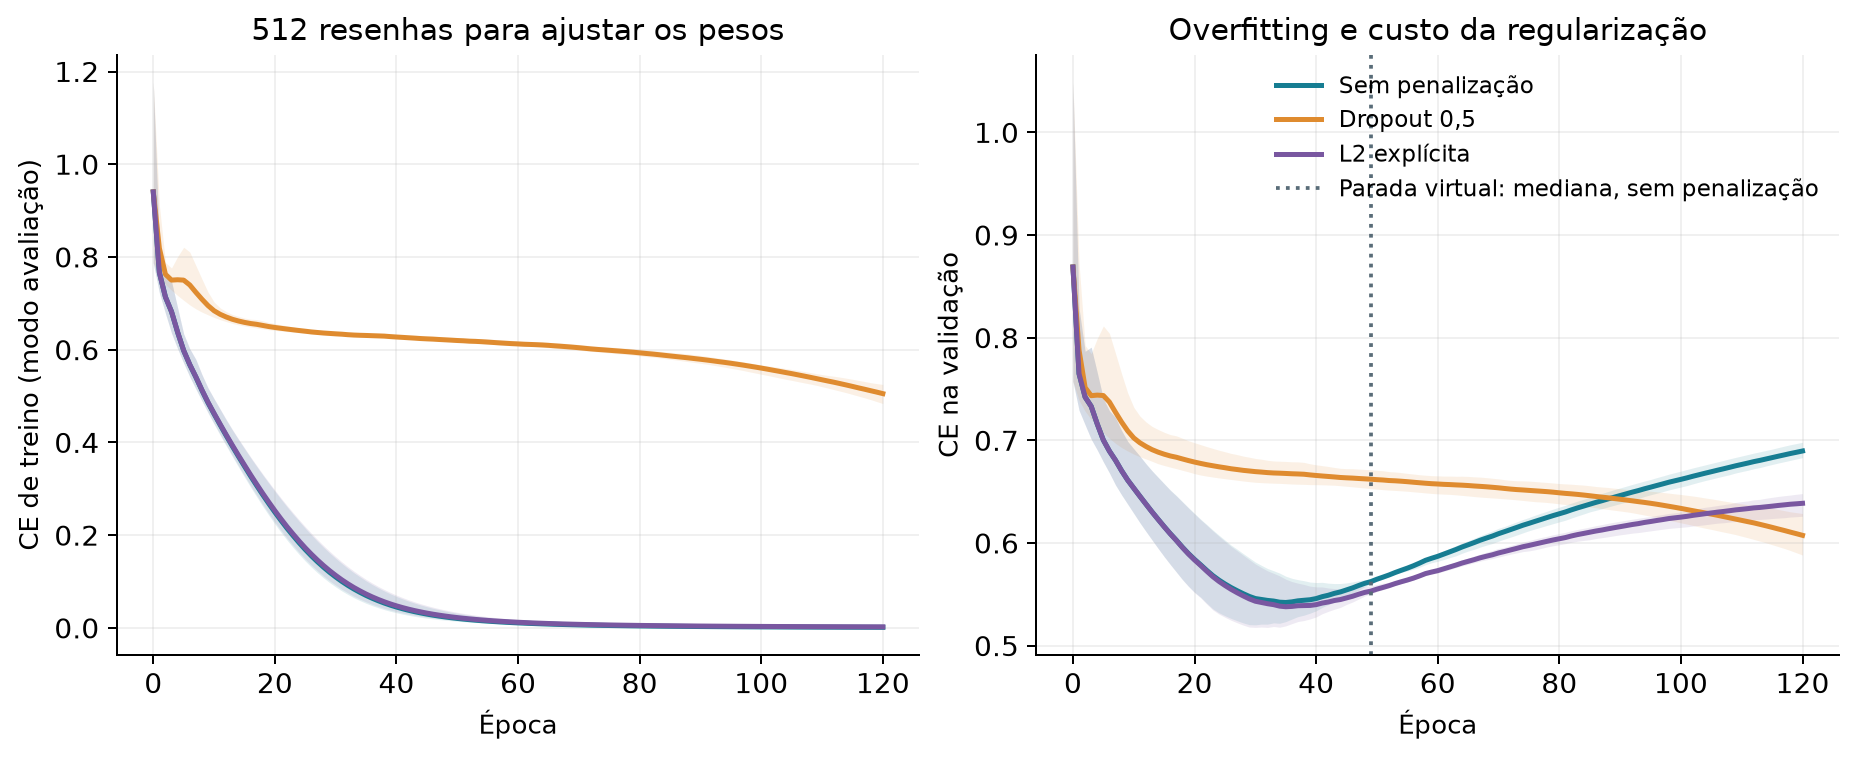

,variante,semente,época selecionada,parada virtual
0,dropout,17,120,120
1,dropout,29,120,120
2,dropout,43,120,120
3,l2,17,30,45
4,l2,29,44,59
5,l2,43,34,49
6,none,17,30,45
7,none,29,43,58
8,none,43,34,49


ce  accuracy
name    checkpoint                    
dropout early       0.610605  0.718424
        final       0.610605  0.718424
l2      early       0.561163  0.724609
        final       0.699044  0.761393
none    early       0.565271  0.722168
        final       0.754681  0.754557

In [8]:
plot('regularization')
display(pd.DataFrame([{'variante':r['name'],'semente':r['seed'],'época selecionada':r['early_epoch'],'parada virtual':r['virtual_stop_epoch']} for r in records if r['group']=='regularization']))
display(audit.loc[audit.group=='regularization'].groupby(['name','checkpoint'])[['ce','accuracy']].mean())

## 5. Double descent em um caso controlado

**Prince 8.4-8.5; slides Desempenho e Generalização, páginas 30-37; Belkin et al.** Aqui mudamos explicitamente para regressão sintética: 64 exemplos de treino, 2.048 de teste, ruído de desvio 0,3 e 20 sementes fixadas. Uma camada ReLU aleatória fica congelada; ajustamos só p coeficientes de saída por mínimos quadrados de norma mínima ou ridge. As larguras são aninhadas dentro de cada semente. O limiar p/n=1 conta apenas os coeficientes ajustados, não todos os pesos congelados. Os gráficos mostram mediana e intervalo interquartil; todos os casos e os valores extremos ficam no CSV. Este experimento não estabelece double descent na CNN do IMDb e não é uma reprodução integral da rede treinada no livro.

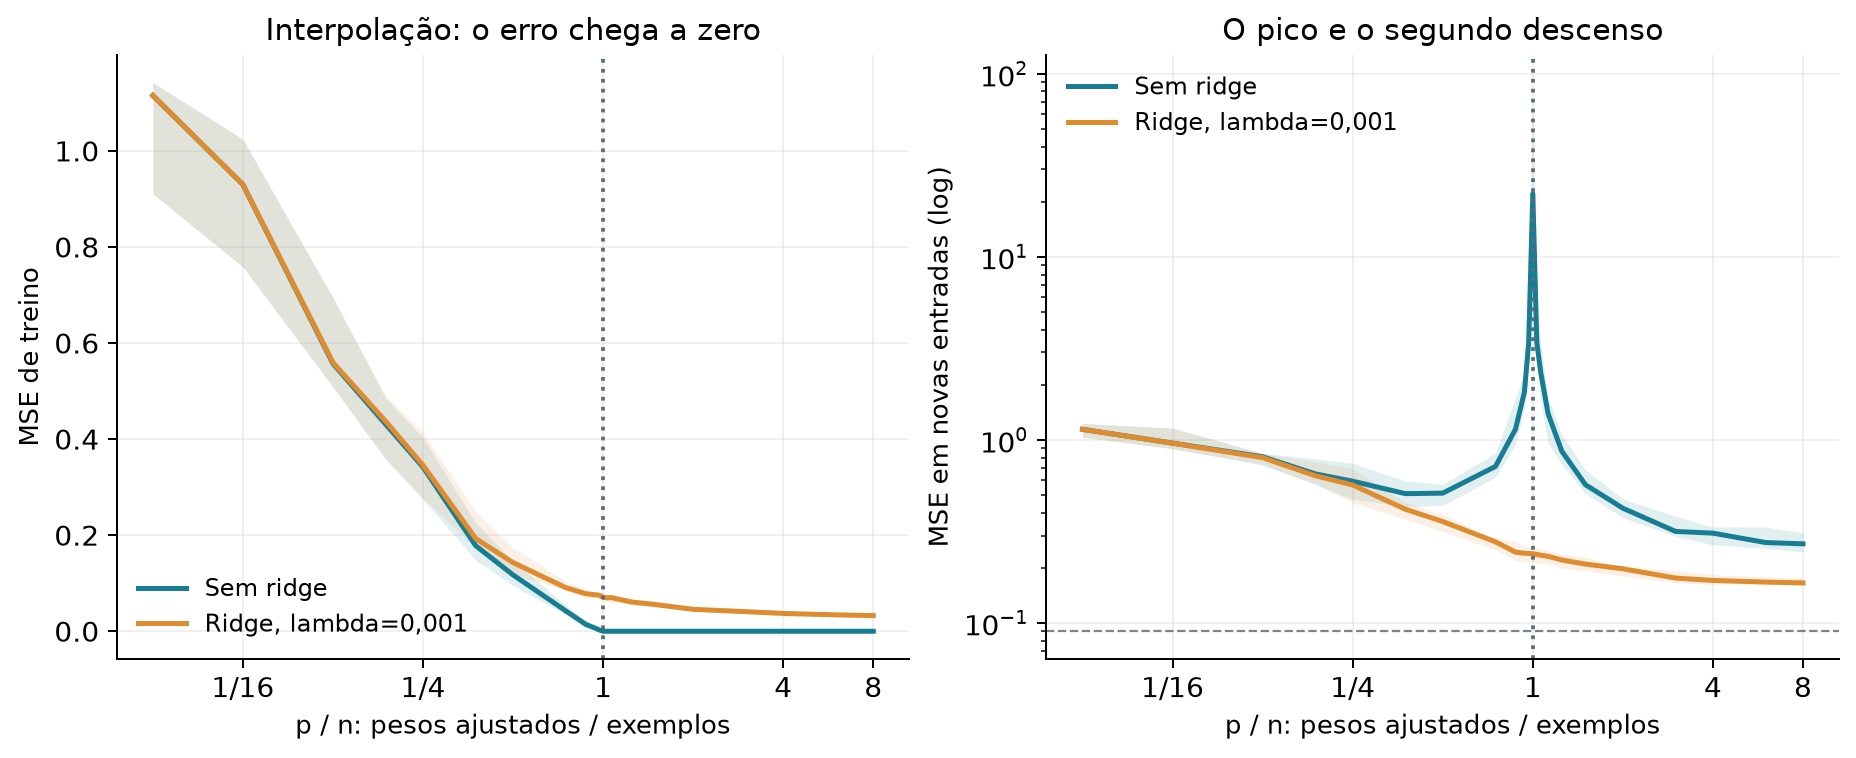

,train_mse,test_mse,coefficient_norm
p,,,
24,1.781083e-01,0.508172,11.283079
64,9.964787e-29,22.090608,150.435749
512,1.096138e-29,0.270269,15.043844


In [9]:
plot('double_descent')
dd=pd.read_csv(Q/'double_descent.csv')
display(dd.loc[(dd['lambda']==0)&dd.p.isin([24,64,512])].groupby('p')[['train_mse','test_mse','coefficient_norm']].median())
assert len(dd)==880 and set(dd.seed)==set(cfg['double_descent']['seeds'])

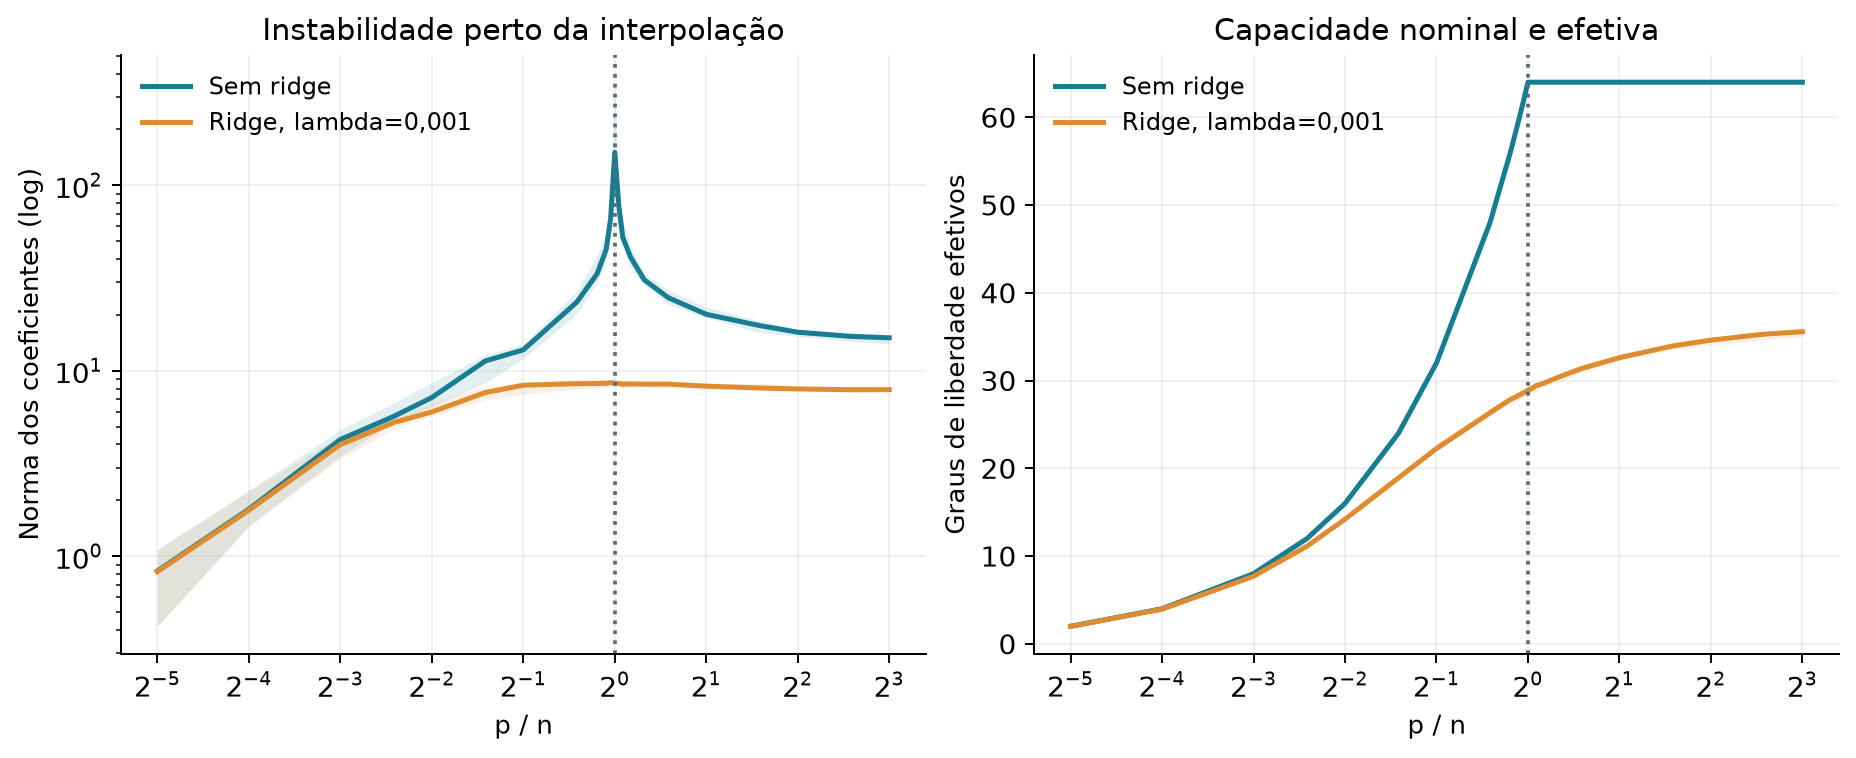

Noise variance: 0.09


,test_mse,effective_df
lambda,,
0.000,22.090608,64.000000
0.001,0.238459,28.908374


In [10]:
plot('double_descent_mechanism')
print('Noise variance:',cfg['double_descent']['noise_sd']**2)
display(dd.loc[dd.p==64].groupby('lambda')[['test_mse','effective_df']].median())

### Reconstruir um interpolador real, sem escolher uma semente favorável

Usamos a primeira semente do protocolo e p=n. O verificador externo repete a conferência para os 880 casos. O erro quase nulo de treino e o erro em novas entradas respondem a perguntas diferentes.

In [11]:
import sys
sys.path.insert(0,str(ROOT/'src'))
from imdb_lab.didactic_toys import synthetic_case
spec=cfg['double_descent'];seed=spec['seeds'][0];p=spec['train_n']
x,xt,y,yt,f,ft,w=synthetic_case(seed,spec)
with np.load(Q/'double_descent_weights.npz') as a: beta=a[f'seed{seed}_p{p}_lambda0']
prediction=np.maximum(x@w[:,:p],0)@beta/np.sqrt(p)
np.testing.assert_allclose(prediction,y,atol=1e-8)
print('MSE de treino reconstruído:',float(np.mean((prediction-y)**2)))

MSE de treino reconstruído: 1.4360226883972926e-28


## Auditoria interna e limites

Os 42 checkpoints foram avaliados depois de congelar as escolhas. As taxas dos otimizadores ficaram próximas em acurácia; profundidade adicional ajustou mais o treino e também elevou a CE de validação. A rede residual escalada melhorou em relação ao residual sem escala neste protocolo, mas a rede rasa continuou competitiva. Na regularização, parar por CE reduziu CE sem necessariamente elevar acurácia. São observações condicionais a esta representação, orçamento e três sementes, sem inferência de superioridade universal. As faixas mín.-máx. de três sementes não são intervalos de confiança populacionais.

In [12]:
display(audit.groupby(['group','name','checkpoint'])[['accuracy','ce']].agg(['mean','min','max']))
evidence=read('results/didactic/verification.json')
assert evidence['status']=='passed'
display(evidence['evidence'])
correction_path=Q/'numerical_audit_correction.json'
if correction_path.exists(): display(json.loads(correction_path.read_text()))

accuracy                      \
                                                  mean       min       max   
group          name               checkpoint                                 
architectures  plain_1            final       0.857747  0.853027  0.865723   
               plain_12           final       0.781087  0.767578  0.789062   
               plain_4            final       0.824219  0.811035  0.832031   
               residual_12_raw    final       0.656413  0.629395  0.695312   
               residual_12_scaled final       0.831543  0.828613  0.833008   
optimizers     adam_lr0.0003      final       0.841471  0.836426  0.846191   
               momentum_lr0.003   final       0.841309  0.837402  0.847168   
               sgd_lr0.03         final       0.841146  0.834473  0.848633   
regularization dropout            early       0.718424  0.679688  0.754395   
                                  final       0.718424  0.679688  0.754395   
               l2                 early       0.724609  0.702637  0.742188   
                                  final       0.761393  0.740723  0.779297   
               none               early       0.722168  0.696777  0.741699   
                                  final       0.754557  0.731934  0.775879   

                                                    ce                      
                                                  mean       min       max  
group          name               checkpoint                                
architectures  plain_1            final       0.336844  0.335698  0.338513  
               plain_12           final       1.590655  1.316394  1.734942  
               plain_4            final       0.651852  0.633029  0.683942  
               residual_12_raw    final       1.071896  0.863775  1.248132  
               residual_12_scaled final       0.525383  0.499119  0.550561  
optimizers     adam_lr0.0003      final       0.382557  0.370431  0.401018  
               momentum_lr0.003   final       0.379556  0.366548  0.397197  
               sgd_lr0.03         final       0.379515  0.367221  0.396943  
regularization dropout            early       0.610605  0.588433  0.630126  
                                  final       0.610605  0.588433  0.630126  
               l2                 early       0.561163  0.514404  0.601228  
                                  final       0.699044  0.634695  0.741451  
               none               early       0.565271  0.516866  0.605372  
                                  final       0.754681  0.687582  0.790658

{'data': '6144/1536/2048 balanced, text-disjoint internal roles use only the original cleaned training pool; representation fitted on the 6144 training rows.',
 'training': 'All 51 trajectories, paired starts and minibatches, equal-size residual ablations, validation-only rate selection and causal early-stop decisions verified.',
 'audit': '42 frozen checkpoints replayed on CPU; per-review probabilities, cross-entropy and accuracy match the single post-freeze internal audit.',
 'initialization': 'All gain/seed/layer measurements obey the independently checked positive-homogeneity scaling of a bias-free ReLU chain.',
 'quadratic': 'The GD trajectories match the exact eigenvalue recurrence, including the prescribed unstable rate above 2/lambda_max.',
 'double_descent': 'All 880 conditions across 20 fixed seeds replayed from stored coefficients; exact interpolation, minimum norm and ridge normal equations checked.'}

{'reason': 'Independent CPU checkpoint replay detected a training/audit precision-policy mismatch. Initial audit used the NVIDIA default TF32 policy; training had explicitly disabled TF32.',
 'maximum_probability_difference_in_first_failing_checkpoint': 0.01529524,
 'action': 'Disable TF32 explicitly in audit, repeat all 51 training runs with the unchanged configuration/seeds, then repeat the frozen audit. Check equality of trained parameter arrays against the first execution.',
 'configuration_changed': False,
 'architecture_or_rate_selection_changed': False,
 'initial_frozen_sha256': '7e9923d7dac1bd65770d96ece4a35cd964a864fea034ffa74c4bb37bd8df5fb4',
 'initial_audit_sha256': '1d8d84606d48c0bd9e536e4765c1c66595b85327d99bf4e5a1227a04a0cc8299',
 'status': 'passed',
 'repeated_checkpoint_archives': 60,
 'trained_parameter_arrays_bit_identical': True,
 'optimizer_choices_identical': True,
 'default_nvidia_matmul_tf32_confirmed': True,
 'corrected_frozen_sha256': 'cf2f688638093d92e87e84834

## Fontes e apresentação

As referências e os localizadores estão abaixo. Os PDFs dos slides/livro permanecem no acervo do grupo, sem redistribuição no repositório. As figuras PNG e SVG em `results/didactic/figures` podem ser usadas diretamente na apresentação. Para uma fala de 8-10 minutos, escolha um gráfico de otimização, um de profundidade/inicialização, um de overfitting e o de double descent. O experimento de steering do Qwen permanece no notebook próprio e funciona como outra forma de intervenção em representações internas.

In [13]:
display(pd.DataFrame(read('results/didactic/source_references.json')['references'])[['id','title','locators','url']].fillna(''))
print('Reproduzir a verificação: python verify_didactic.py')
print('Treino não repetido por este notebook.')

,id,title,locators,url
0,prince,"Simon J. D. Prince, Understanding Deep Learning",6.1-6.5; 7.5; 8.4-8.5; 9.1 e 9.3; 11.1-11.3,https://udlbook.github.io/udlbook/
1,slides06,MAE5920: Ajuste de Modelos,páginas do arquivo 26-39 (momentum e Adam),
2,slides07,MAE5920: Gradientes e Inicialização,páginas do arquivo 31-42,
3,slides08,MAE5920: Desempenho e Generalização,páginas do arquivo 30-37 (duplo descenso),
4,slides09,MAE5920: Regularização,páginas do arquivo 7-17 e 29-36,
5,slides11,MAE5920: Redes Residuais,páginas do arquivo 5-18,
6,adam,"Kingma e Ba, Adam: A Method for Stochastic Opt...",,https://arxiv.org/abs/1412.6980
7,belkin,"Belkin et al., Reconciling modern machine lear...",,https://arxiv.org/abs/1812.11118


Reproduzir a verificação: python verify_didactic.py
Treino não repetido por este notebook.
